In [24]:
import pandas as pd
import numpy as np

# Load the combined dataset
file_path = 'dataset.csv'
df = pd.read_csv(file_path)

print(f"Dataset Shape: {df.shape}")
print("-" * 30)

print("First 5 rows of the dataset:")
print(df.head())
print("-" * 30)

print("Dataset Information:")
print(df.info())
print("-" * 30)

print("Missing values per column:")
print(df.isnull().sum())

Dataset Shape: (6506, 6)
------------------------------
First 5 rows of the dataset:
             Timestamp  Temperature    pH  Turbidity    TDS  Label
0  2026-01-14 16:12:00        30.12  6.97        9.0  21.80      0
1  2026-01-14 16:12:00        30.19  6.96        0.0  22.38      0
2  2026-01-14 16:12:01        30.12  6.90        0.0  22.11      0
3  2026-01-14 16:12:02        30.12  7.00        0.0  20.89      0
4  2026-01-14 16:12:03        30.19  7.00        0.0  22.38      0
------------------------------
Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6506 entries, 0 to 6505
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Timestamp    6506 non-null   object 
 1   Temperature  6506 non-null   float64
 2   pH           6506 non-null   float64
 3   Turbidity    6506 non-null   float64
 4   TDS          6506 non-null   float64
 5   Label        6506 non-null   int64  
dtypes: float64(4),

--- Class Counts ---
Label 0 (Clean): 3500 samples
Label 1 (Polluted): 3006 samples


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_17316\2840105038.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=label_counts.index, y=label_counts.values, palette='viridis')


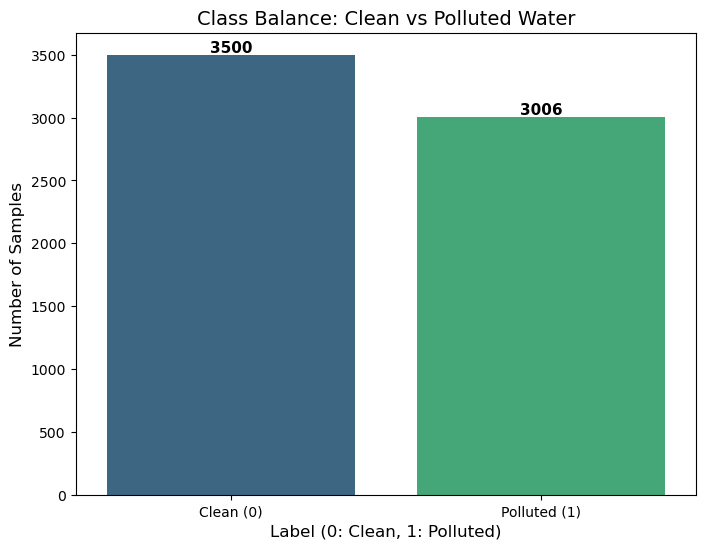

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calculate the counts for each label
label_counts = df['Label'].value_counts().sort_index()

print("--- Class Counts ---")
for label, count in label_counts.items():
    status = "Clean" if label == 0 else "Polluted"
    print(f"Label {label} ({status}): {count} samples")

# 2. Plotting the Class Balance
plt.figure(figsize=(8, 6))
sns.barplot(x=label_counts.index, y=label_counts.values, palette='viridis')

# Adding labels and title
plt.title('Class Balance: Clean vs Polluted Water', fontsize=14)
plt.xlabel('Label (0: Clean, 1: Polluted)', fontsize=12)
plt.ylabel('Number of Samples', fontsize=12)
plt.xticks(ticks=[0, 1], labels=['Clean (0)', 'Polluted (1)'])

# Add the counts on top of the bars
for i, count in enumerate(label_counts.values):
    plt.text(i, count + 20, str(count), ha='center', fontsize=11, fontweight='bold')

# Save the plot
plt.savefig('class_balance.png')
plt.show() # Note: Use plt.show() in your local IDE to see it immediately

✅ Boxplots saved as 'outlier_boxplots.png'.

--- Outlier Count (IQR Method) ---
Temperature: 1289 outliers detected
pH: 1191 outliers detected
Turbidity: 500 outliers detected
TDS: 0 outliers detected


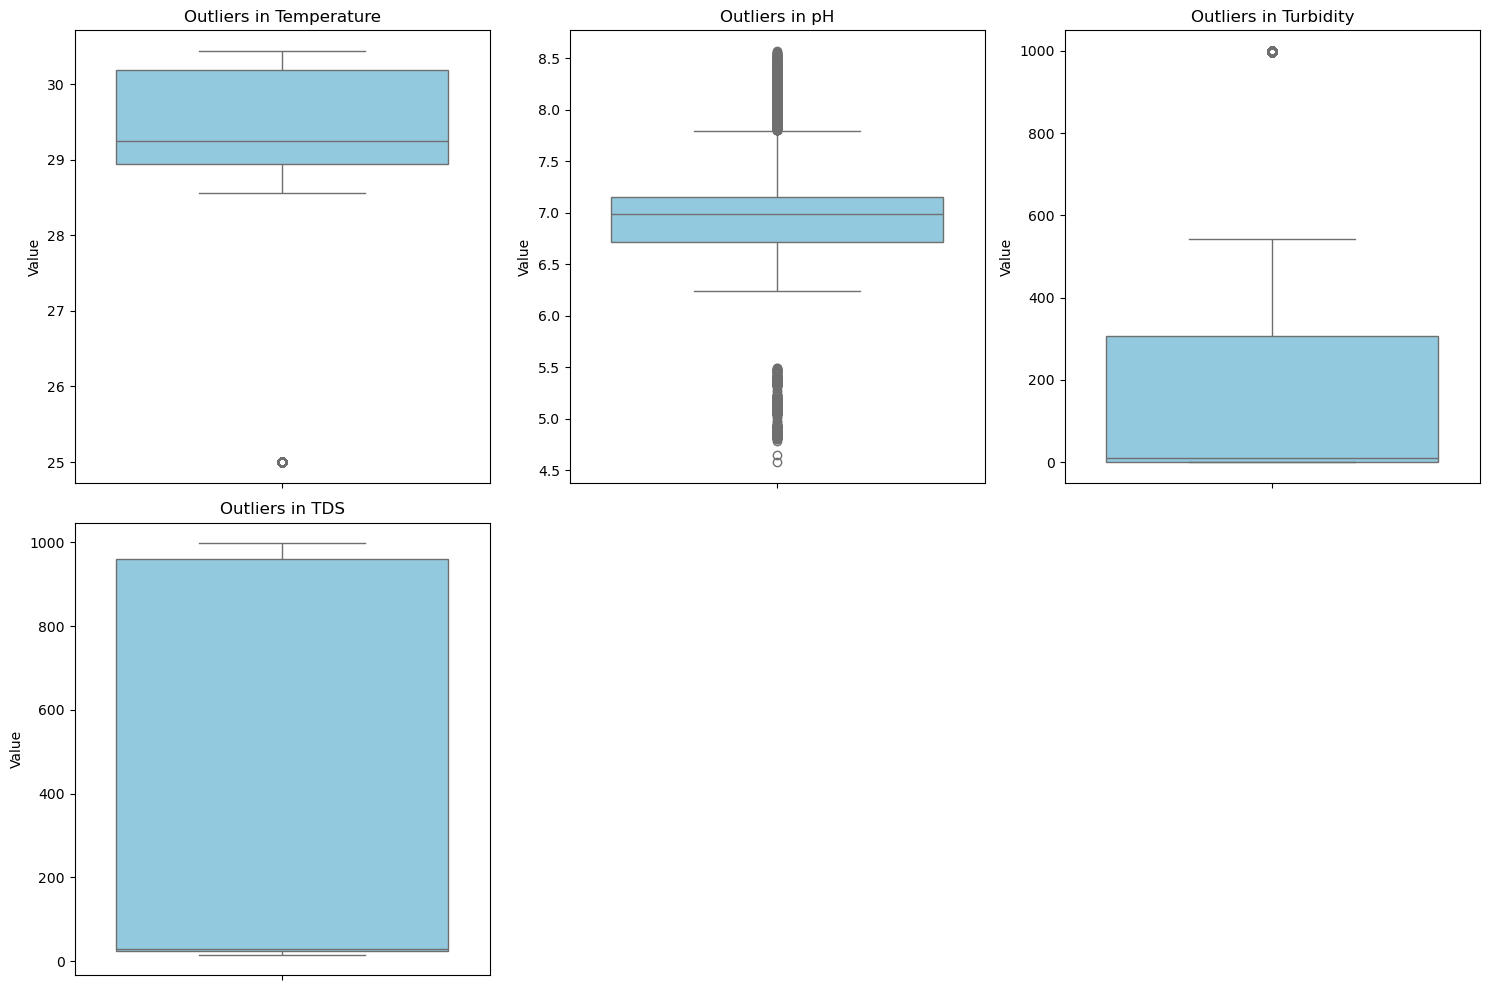

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Select the sensor columns for outlier detection
features = ['Temperature', 'pH', 'Turbidity', 'TDS']

# 2. Create boxplots to visualize outliers
# We use subplots to see all sensors side-by-side
plt.figure(figsize=(15, 10))

for i, feature in enumerate(features):
    plt.subplot(2, 3, i+1)
    sns.boxplot(y=df[feature], color='skyblue')
    plt.title(f'Outliers in {feature}', fontsize=12)
    plt.ylabel('Value')

plt.tight_layout()
plt.savefig('outlier_boxplots.png')
print("✅ Boxplots saved as 'outlier_boxplots.png'.")

# 3. Programmatic Check: Calculate number of outliers using IQR method
print("\n--- Outlier Count (IQR Method) ---")
for feature in features:
    Q1 = df[feature].quantile(0.25)
    Q3 = df[feature].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = df[(df[feature] < lower_bound) | (df[feature] > upper_bound)]
    print(f"{feature}: {len(outliers)} outliers detected")

✅ Fixed Correlation Heatmap saved as 'correlation_heatmap_fixed.png'.


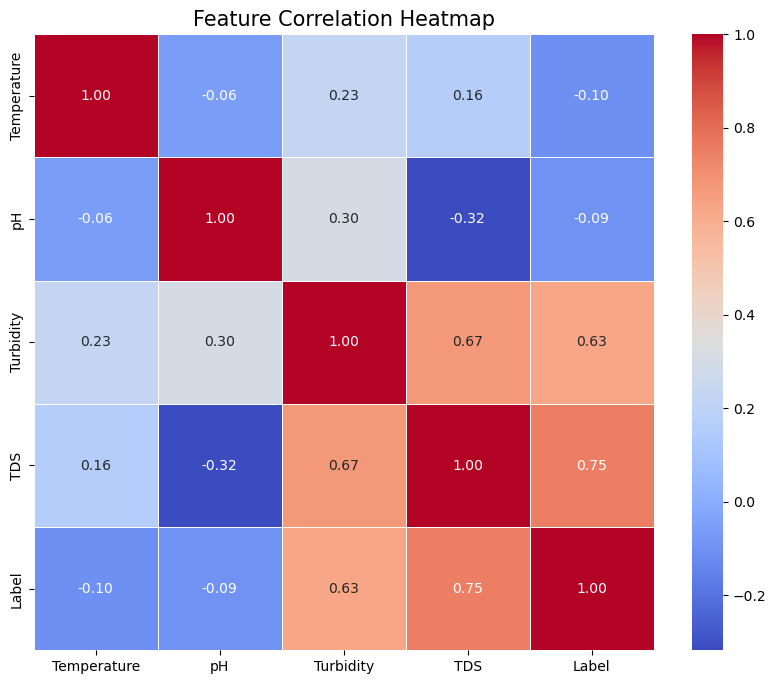

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calculate the correlation matrix (using numeric columns only)
corr_matrix = df.corr(numeric_only=True)

# 2. Plotting the Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)

plt.title('Feature Correlation Heatmap', fontsize=15)

# Save the plot
plt.savefig('correlation_heatmap_fixed.png')
print("✅ Fixed Correlation Heatmap saved as 'correlation_heatmap_fixed.png'.")

✅ Scatter Plot saved as 'class_separation_scatter.png'.


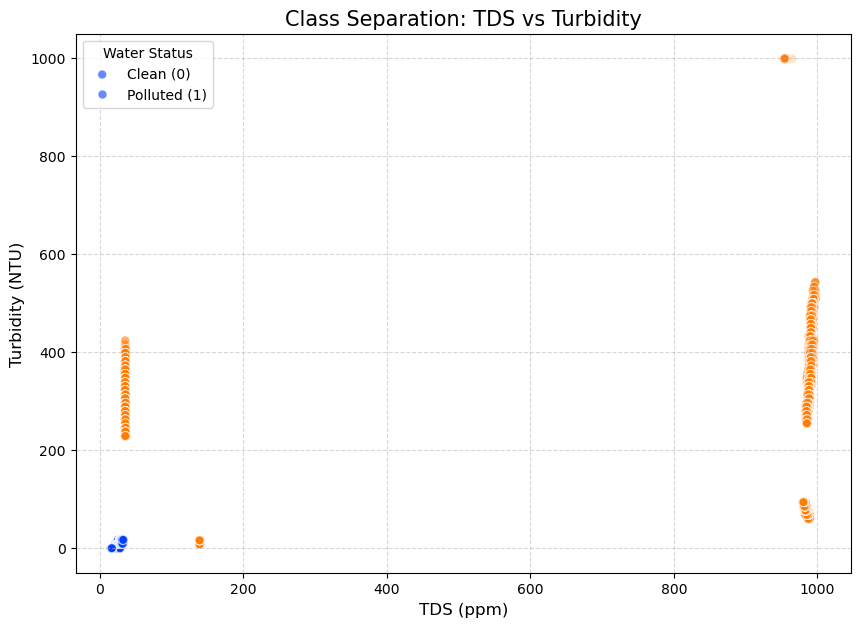

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

sensor_x = 'TDS'
sensor_y = 'Turbidity'

plt.figure(figsize=(10, 7))

sns.scatterplot(data=df, x=sensor_x, y=sensor_y, hue='Label', 
                palette='bright', alpha=0.6, s=40)

# 3. Add styling
plt.title(f'Class Separation: {sensor_x} vs {sensor_y}', fontsize=15)
plt.xlabel(f'{sensor_x} (ppm)', fontsize=12)
plt.ylabel(f'{sensor_y} (NTU)', fontsize=12)
plt.legend(title='Water Status', labels=['Clean (0)', 'Polluted (1)'])
plt.grid(True, linestyle='--', alpha=0.5)

# Save the plot
plt.savefig('class_separation_scatter.png')
print("✅ Scatter Plot saved as 'class_separation_scatter.png'.")

cnnlstm

In [29]:
features = ['Temperature', 'pH', 'Turbidity', 'TDS']

X = df[features].values
y = df['Label'].values


In [30]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


In [31]:
from sklearn.preprocessing import MinMaxScaler
import joblib

scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

joblib.dump(scaler, "aqua_sense_scaler.pkl")


['aqua_sense_scaler.pkl']

In [32]:
# Reshape to (samples, steps, channels)
X_train_seq = X_train_scaled.reshape(X_train_scaled.shape[0], X_train_scaled.shape[1], 1)
X_test_seq  = X_test_scaled.reshape(X_test_scaled.shape[0],  X_test_scaled.shape[1],  1)

print(X_train_seq.shape)  # (N, 5, 1)


(5204, 4, 1)


In [33]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, LSTM, Dense, Dropout

model = Sequential([
    Conv1D(32, kernel_size=2, activation='relu', input_shape=(X_train_seq.shape[1], 1)),
    MaxPooling1D(2),
    Dropout(0.5),

    LSTM(8),
    Dropout(0.5),

    Dense(8, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()


f:\fleming\anaconda\anaconda\envs\myenv\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_2 (Conv1D)               │ (None, 3, 32)          │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 1, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 1, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 8)              │         1,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │            72 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,489 (5.82 KB)

 Trainable params: 1,489 (5.82 KB)

 Non-trainable params: 0 (0.00 B)

In [34]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    filepath='cnnlstm_model.h5',
    monitor='val_loss',
    save_best_only=True,
    save_weights_only=False,
    verbose=1
)

history = model.fit(
    X_train_seq, y_train,
    epochs=25,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop, checkpoint],
    verbose=1
)


Epoch 1/25
129/131 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.5179 - loss: 0.6914
Epoch 1: val_loss improved from None to 0.68974, saving model to cnnlstm_model.h5


131/131 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.5297 - loss: 0.6907 - val_accuracy: 0.5264 - val_loss: 0.6897
Epoch 2/25
126/131 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.5395 - loss: 0.6884
Epoch 2: val_loss improved from 0.68974 to 0.68689, saving model to cnnlstm_model.h5


131/131 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.5426 - loss: 0.6868 - val_accuracy: 0.5264 - val_loss: 0.6869
Epoch 3/25
128/131 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5424 - loss: 0.6846
Epoch 3: val_loss improved from 0.68689 to 0.67460, saving model to cnnlstm_model.h5


131/131 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.5436 - loss: 0.6828 - val_accuracy: 0.5264 - val_loss: 0.6746
Epoch 4/25
129/131 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5693 - loss: 0.6627
Epoch 4: val_loss improved from 0.67460 to 0.59425, saving model to cnnlstm_model.h5


131/131 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.5868 - loss: 0.6522 - val_accuracy: 0.8655 - val_loss: 0.5943
Epoch 5/25
127/131 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7016 - loss: 0.5955
Epoch 5: val_loss improved from 0.59425 to 0.45451, saving model to cnnlstm_model.h5


131/131 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.7093 - loss: 0.5752 - val_accuracy: 0.8780 - val_loss: 0.4545
Epoch 6/25
128/131 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7606 - loss: 0.5126
Epoch 6: val_loss improved from 0.45451 to 0.37191, saving model to cnnlstm_model.h5


... (13 outputs left out)

131/131 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9318 - loss: 0.1832 - val_accuracy: 0.9789 - val_loss: 0.0647
Epoch 20/25
126/131 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9345 - loss: 0.1713
Epoch 20: val_loss improved from 0.06470 to 0.04999, saving model to cnnlstm_model.h5


131/131 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.9325 - loss: 0.1818 - val_accuracy: 0.9914 - val_loss: 0.0500
Epoch 21/25
126/131 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9299 - loss: 0.1959
Epoch 21: val_loss did not improve from 0.04999
131/131 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9296 - loss: 0.1903 - val_accuracy: 0.9856 - val_loss: 0.0503
Epoch 22/25
126/131 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9369 - loss: 0.1814
Epoch 22: val_loss improved from 0.04999 to 0.04048, saving model to cnnlstm_model.h5


131/131 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9335 - loss: 0.1813 - val_accuracy: 0.9933 - val_loss: 0.0405
Epoch 23/25
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9367 - loss: 0.1633
Epoch 23: val_loss improved from 0.04048 to 0.03917, saving model to cnnlstm_model.h5


131/131 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9387 - loss: 0.1691 - val_accuracy: 0.9933 - val_loss: 0.0392
Epoch 24/25
124/131 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9421 - loss: 0.1660
Epoch 24: val_loss did not improve from 0.03917
131/131 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9464 - loss: 0.1560 - val_accuracy: 0.9866 - val_loss: 0.0421
Epoch 25/25
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9405 - loss: 0.1761
Epoch 25: val_loss did not improve from 0.03917
131/131 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9423 - loss: 0.1645 - val_accuracy: 0.9894 - val_loss: 0.0399


In [35]:
loss, acc = model.evaluate(X_test_seq, y_test, verbose=0)
print(f"Test Accuracy: {acc*100:.2f}%")


Test Accuracy: 98.62%


In [50]:
import numpy as np
import joblib
from tensorflow.keras.models import load_model

# -------------------------------------------------------
# Load model and scaler
# -------------------------------------------------------
model = load_model("cnnlstm_model.h5")
scaler = joblib.load("aqua_sense_scaler.pkl")

# -------------------------------------------------------
# Input string (PASTE YOUR DATA HERE)
# Format: Timestamp,Temperature,pH,Turbidity,TDS
# -------------------------------------------------------
input_string = "2026-01-14 16:30:36,25.00,6.79,216.00,64.03"

# -------------------------------------------------------
# Parse input
# -------------------------------------------------------
parts = input_string.strip().split(",")

if len(parts) != 5:
    raise ValueError("Input must have exactly 5 comma-separated values: Timestamp,Temperature,pH,Turbidity,TDS")

# Ignore timestamp for prediction
temperature = float(parts[1])
ph = float(parts[2])
turbidity = float(parts[3])
tds = float(parts[4])

# Feature vector
X = np.array([[temperature, ph, turbidity, tds]])

# -------------------------------------------------------
# Scale and reshape
# -------------------------------------------------------
X_scaled = scaler.transform(X)

# Reshape to (samples, steps, channels)
X_seq = X_scaled.reshape(1, X_scaled.shape[1], 1)

# -------------------------------------------------------
# Predict
# -------------------------------------------------------
prob = model.predict(X_seq)[0][0]
pred = 1 if prob >= 0.5 else 0

# -------------------------------------------------------
# Output
# -------------------------------------------------------
print("Input:", input_string)
print(f"Model output probability: {prob:.4f}")

if pred == 0:
    print("Prediction: CLEAN water")
else:
    print("Prediction: POLLUTED water")


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 557ms/step
Input: 2026-01-14 16:30:36,25.00,6.79,216.00,64.03
Model output probability: 0.3188
Prediction: CLEAN water


In [56]:
import numpy as np
import joblib
from tensorflow.keras.models import load_model

# -------------------------------------------------------
# Load model and scaler
# -------------------------------------------------------
model = load_model("cnnlstm_model.h5")
scaler = joblib.load("aqua_sense_scaler.pkl")

# -------------------------------------------------------
# Input string
# Format: Timestamp,Temperature,pH,Turbidity,TDS
# -------------------------------------------------------
input_string = "2026-01-14 16:30:36,25.00,6.29,54.00,16.95"

# -------------------------------------------------------
# Parse input
# -------------------------------------------------------
parts = input_string.strip().split(",")

if len(parts) != 5:
    raise ValueError("Input must have exactly 5 comma-separated values: Timestamp,Temperature,pH,Turbidity,TDS")

# Ignore timestamp for prediction
temperature = float(parts[1])
ph = float(parts[2])
turbidity = float(parts[3])
tds = float(parts[4])

# Feature vector (4 features)
X = np.array([[temperature, ph, turbidity, tds]])

# -------------------------------------------------------
# Scale and reshape
# -------------------------------------------------------
X_scaled = scaler.transform(X)
X_seq = X_scaled.reshape(1, X_scaled.shape[1], 1)

# -------------------------------------------------------
# Predict and Custom Threshold Logic
# -------------------------------------------------------
prob = model.predict(X_seq, verbose=0)[0][0]

# SETTING CUSTOM THRESHOLD AT 0.2
THRESHOLD = 0.2
pred = 1 if prob >= THRESHOLD else 0

# -------------------------------------------------------
# Output
# -------------------------------------------------------
print("-" * 40)
print("Input:", input_string)
print(f"Model output probability: {prob:.4f}")
print(f"Decision Boundary: {THRESHOLD}")

if pred == 0:
    print("Prediction: CLEAN water")
else:
    # Adding a note if it was triggered by the sensitive threshold
    if prob < 0.5:
        print("Prediction: POLLUTED water (Caution: Low-level contaminants detected)")
    else:
        print("Prediction: POLLUTED water (High confidence)")
print("-" * 40)

----------------------------------------
Input: 2026-01-14 16:30:36,25.00,6.29,54.00,16.95
Model output probability: 0.1073
Decision Boundary: 0.2
Prediction: CLEAN water
----------------------------------------
